# Solutions to notebook 2: Fourier differentiation and the FFT

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/02_fourier_differentiation_and_fft.ipynb)

Worked solutions to the exercises at the end of [notebook 2](../notebooks/02_fourier_differentiation_and_fft.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# functions from notebook 2
def fourier_diff_matrix(N):
    """First-derivative matrix for the periodic grid of N points (N even)."""
    if N % 2:
        raise ValueError("N must be even")
    h = 2 * np.pi / N
    k = np.arange(N)[:, None] - np.arange(N)[None, :]          # i - j
    D = np.zeros((N, N))
    off = k != 0
    D[off] = 0.5 * (-1.0) ** k[off] / np.tan(k[off] * h / 2)
    return D

def fourier_diff2_matrix(N):
    """Second-derivative matrix for the periodic grid of N points (N even)."""
    if N % 2:
        raise ValueError("N must be even")
    h = 2 * np.pi / N
    k = np.arange(N)[:, None] - np.arange(N)[None, :]
    D2 = np.full((N, N), -np.pi**2 / (3 * h**2) - 1 / 6)
    off = k != 0
    D2[off] = -0.5 * (-1.0) ** k[off] / np.sin(k[off] * h / 2) ** 2
    return D2

def fft_derivative(v, order=1):
    """Spectral derivative of real periodic samples v on the grid x_j = 2πj/N.

    For odd orders the highest (Nyquist) mode is set to zero, because on the grid it cannot be
    told apart from its mirror image and its derivative is ambiguous.
    """
    N = len(v)
    k = np.fft.fftfreq(N, d=1 / N)                             # 0, 1, ..., N/2-1, -N/2, ..., -1
    factor = (1j * k) ** order
    if order % 2 and N % 2 == 0:
        factor[N // 2] = 0
    return np.real(np.fft.ifft(factor * np.fft.fft(v)))

def fourier_interpolate(v, M):
    """Values of the trigonometric interpolant of v (N samples, N even) on the periodic grid of M > N points."""
    N = len(v)
    v_hat = np.fft.fft(v)
    padded = np.zeros(M, dtype=complex)
    padded[: N // 2] = v_hat[: N // 2]                         # k = 0, ..., N/2 - 1
    padded[M - N // 2 + 1 :] = v_hat[N // 2 + 1 :]             # k = -N/2 + 1, ..., -1
    padded[N // 2] = padded[M - N // 2] = v_hat[N // 2] / 2    # the Nyquist mode, shared between ±N/2
    return np.real(np.fft.ifft(padded)) * M / N

def low_pass(v, cutoff):
    """Remove all wavenumbers above the cut-off from the periodic samples v."""
    v_hat = np.fft.fft(v)
    v_hat[np.abs(np.fft.fftfreq(len(v), 1 / len(v))) > cutoff] = 0
    return np.real(np.fft.ifft(v_hat))

r_crank, l_rod = 1.0, 3.0

def position(theta):
    return r_crank * np.cos(theta) + np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)

def velocity(theta):                        # ds/dθ, exact
    root = np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)
    return -r_crank * np.sin(theta) - r_crank**2 * np.sin(theta) * np.cos(theta) / root

def acceleration(theta):                    # d²s/dθ², exact
    root = np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)
    return (-r_crank * np.cos(theta) - r_crank**2 * np.cos(2 * theta) / root
            - r_crank**4 * np.sin(theta) ** 2 * np.cos(theta) ** 2 / root**3)

## Exercise 1

For $u(x) = e^{\sin x}$ the third derivative is
$u''' = (\cos^3x - 3\sin x\cos x - \cos x)\,e^{\sin x}$. Compute it with
`fft_derivative(u, 3)` for $N = 8, 16, 24, 32$ and tabulate the largest error. Then compute it
as `D @ D @ D @ u` with `fourier_diff_matrix` and confirm that the two results agree to
rounding for $N = 32$.

The function is analytic everywhere in the complex plane, so the error should fall faster than
any geometric rate until it reaches the rounding level. For the comparison with the matrix, recall that the third derivative is of odd order:
`fft_derivative` sets the Nyquist mode to zero, and so does the matrix, because $D$ applied to
the sawtooth $(-1)^j$ is zero. The two results should therefore agree to rounding.

In [3]:
def u_exact(x):
    return np.exp(np.sin(x))

def u_third(x):
    return (np.cos(x) ** 3 - 3 * np.sin(x) * np.cos(x) - np.cos(x)) * np.exp(np.sin(x))

print("   N    largest error of fft_derivative(u, 3)")
third_errors = {}
for N in (8, 16, 24, 32):
    x = 2 * np.pi * np.arange(N) / N
    third_errors[N] = np.abs(fft_derivative(u_exact(x), 3) - u_third(x)).max()
    print(f"{N:4d} {third_errors[N]:16.1e}")

D = fourier_diff_matrix(32)                                    # x still holds the grid for N = 32
by_matrix = D @ D @ D @ u_exact(x)
difference = np.abs(by_matrix - fft_derivative(u_exact(x), 3)).max()
print(f"N = 32: largest difference between D @ D @ D @ u and the FFT result: {difference:.1e}")

   N    largest error of fft_derivative(u, 3)
   8          8.1e-02
  16          1.2e-05
  24          1.4e-10
  32          4.0e-13
N = 32: largest difference between D @ D @ D @ u and the FFT result: 1.4e-12


In [4]:
# verify: the formula given for u''' against a complex-step derivative of u'', then the errors and the agreement
u_second = lambda z: (np.cos(z) ** 2 - np.sin(z)) * np.exp(np.sin(z))
assert np.abs(np.imag(u_second(x + 1e-30j)) / 1e-30 - u_third(x)).max() < 1e-13
assert third_errors[8] > 1e-2 and third_errors[16] < 1e-4 and third_errors[24] < 1e-9 and third_errors[32] < 1e-11
assert difference < 1e-10 and np.abs(by_matrix - u_third(x)).max() < 1e-10

**Answer.** The largest errors are $8.1\times10^{-2}$, $1.2\times10^{-5}$, $1.4\times10^{-10}$ and
$4\times10^{-13}$ for $N = 8, 16, 24, 32$: four, then five, more digits for every eight points, until
rounding stops the descent. At $N = 32$ the matrix product `D @ D @ D @ u` differs from the FFT
result by about $10^{-12}$, which is rounding error amplified by three differentiations. The
two routes compute the same quantity, the third derivative of the trigonometric interpolant
with its Nyquist mode removed.

## Exercise 2

For $N = 16$ compare the second-derivative matrix $D^{(2)}$, `fourier_diff2_matrix(N)`, with
the square of the first-derivative matrix, `D @ D`. Show that the difference
$D^{(2)} - D^2$ is a multiple of the matrix with entries $(-1)^{i+j}$, find the multiple, and
explain the result with the Nyquist mode.

Section 2.5 already says where to look: the two matrices can only differ in what they do to the Nyquist mode, the sawtooth $s_j = (-1)^j$. The first-derivative matrix
sends it to zero, so $D^2$ does too. The even-order rule multiplies it by
$(ik)^2 = -(N/2)^2$.

In [5]:
N = 16
D = fourier_diff_matrix(N)
D2 = fourier_diff2_matrix(N)
difference = D2 - D @ D
signs = (-1.0) ** (np.arange(N)[:, None] + np.arange(N)[None, :])
multiple = difference[0, 0]

print("top left corner of D2 - D @ D:")
print(np.round(difference[:4, :6], 10))
print(f"multiple of (-1)^(i+j): {multiple:.6f}      -N/4 = {-N / 4}")
sawtooth = (-1.0) ** np.arange(N)
print(f"applied to the sawtooth: |D s| = {np.abs(D @ sawtooth).max():.1e},  D2 s = {(D2 @ sawtooth)[0]:.1f} s,  -(N/2)² = {-(N / 2) ** 2:.0f}")

top left corner of D2 - D @ D:
[[-4.  4. -4.  4. -4.  4.]
 [ 4. -4.  4. -4.  4. -4.]
 [-4.  4. -4.  4. -4.  4.]
 [ 4. -4.  4. -4.  4. -4.]]
multiple of (-1)^(i+j): -4.000000      -N/4 = -4.0
applied to the sawtooth: |D s| = 5.6e-15,  D2 s = -64.0 s,  -(N/2)² = -64


**By hand.** Any data vector $\mathbf{v}$ contains the sawtooth with the amplitude
$\tfrac1N\sum_j (-1)^j v_j = \tfrac1N\,\mathbf{s}^T\mathbf{v}$. The matrix $D^{(2)}$ multiplies
that component by $-(N/2)^2$, and $D^2$ multiplies it by zero. On every other wave the two
agree. Therefore

$$D^{(2)} - D^2 = -\Big(\frac N2\Big)^2\,\frac1N\,\mathbf{s}\,\mathbf{s}^T = -\frac N4\,\big[(-1)^{i+j}\big] .$$

In [6]:
# verify: the multiple against the hand result -N/4 for three grid sizes, and D2 against the FFT applied to the identity
for n in (8, 16, 32):
    Dn = fourier_diff_matrix(n)
    D2n = fourier_diff2_matrix(n)
    pattern = (-1.0) ** (np.arange(n)[:, None] + np.arange(n)[None, :])
    assert np.abs(D2n - Dn @ Dn + n / 4 * pattern).max() < 1e-11
    assert np.abs(D2n - np.column_stack([fft_derivative(e, 2) for e in np.eye(n)])).max() < 1e-11   # column j = the rule applied to column j of the identity
assert np.abs(D @ sawtooth).max() < 1e-12 and np.allclose(D2 @ sawtooth, -(N / 2) ** 2 * sawtooth)
x = 2 * np.pi * np.arange(N) / N                               # on smooth data the difference is 64 times a tiny Nyquist amplitude
nyquist_amplitude = abs(np.fft.fft(np.exp(np.sin(x)))[N // 2]) / N
print(f"exp(sin x): Nyquist amplitude {nyquist_amplitude:.1e}, largest difference between D2 u and D @ D @ u {np.abs(difference @ np.exp(np.sin(x))).max():.1e}")
assert np.isclose(np.abs(difference @ np.exp(np.sin(x))).max(), (N / 2) ** 2 * nyquist_amplitude, rtol=1e-6) and nyquist_amplitude < 1e-6

exp(sin x): Nyquist amplitude 2.0e-07, largest difference between D2 u and D @ D @ u 1.3e-05


**Answer.** $D^{(2)} - D^2 = -\dfrac N4\,(-1)^{i+j}$, which is $-4\,(-1)^{i+j}$ for $N = 16$. The
difference acts only on the Nyquist mode: differentiating once removes that mode (the rule for
odd orders), so $D^2$ returns zero for the sawtooth, where the true second-derivative matrix
returns $-(N/2)^2 = -64$ times it. On smooth, well-resolved data the Nyquist amplitude is
small and so is the difference: for $e^{\sin x}$ on these 16 points the amplitude is
$2\times10^{-7}$ and the two second derivatives differ by $1.3\times10^{-5}$. When the highest mode matters, for instance in the
stability of a time-stepping scheme (notebook 9), build the second derivative directly.

## Exercise 3

Sample $u(x) = \sin 13x$ on the grid with $N = 16$. Which wavenumber between $-7$ and $8$
has the same samples? Compute `fft_derivative(u)` and compare it with the exact derivative
$13\cos 13x$ at the grid points. What is the largest error, and why is it exactly that number?

By 2.1 the wavenumbers 13 and $13 - 16 = -3$ have the same samples, so on this grid
$\sin 13x_j = \sin(-3x_j) = -\sin 3x_j$. The spectral derivative differentiates the interpolant,
which is $-\sin 3x$, and returns $-3\cos 3x_j$. The exact derivative at the grid points is
$13\cos 13x_j = 13\cos 3x_j$. The error is $16\cos 3x_j$: the grid has mistaken the wavenumber by
exactly $N$.

wavenumbers with a non-zero amplitude: [ 3 -3]  amplitudes: [0.+0.5j 0.-0.5j]
largest error of fft_derivative: 16.000000000000, at the grid points x = [0.     3.1416]


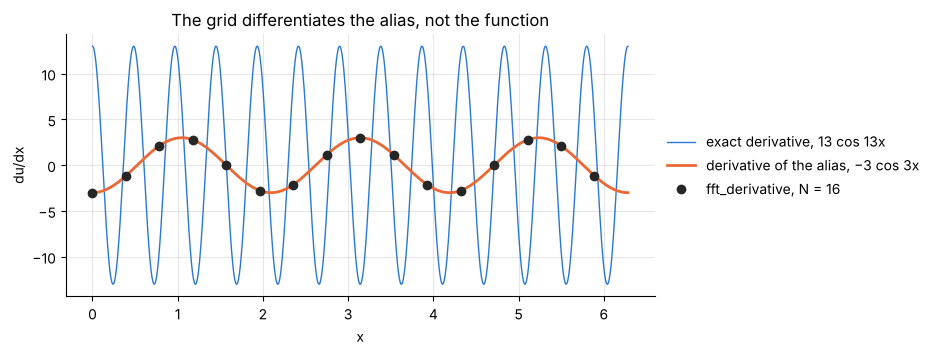

In [7]:
N = 16
x = 2 * np.pi * np.arange(N) / N
u = np.sin(13 * x)
amplitudes = np.fft.fft(u) / N
k = np.fft.fftfreq(N, 1 / N).astype(int)
print("wavenumbers with a non-zero amplitude:", k[np.abs(amplitudes) > 1e-12], " amplitudes:", np.round(amplitudes[np.abs(amplitudes) > 1e-12], 12) + 0)

computed = fft_derivative(u)
error = computed - 13 * np.cos(13 * x)
print(f"largest error of fft_derivative: {np.abs(error).max():.12f}, at the grid points x = {x[np.abs(error) > 16 - 1e-9].round(4)}")

fine = np.linspace(0, 2 * np.pi, 1200)
fig, ax = plt.subplots(figsize=(7.6, 3.4))
ax.plot(fine, 13 * np.cos(13 * fine), lw=1, label="exact derivative, 13 cos 13x")
ax.plot(fine, -3 * np.cos(3 * fine), label="derivative of the alias, −3 cos 3x")
ax.plot(x, computed, "o", color="0.15", ms=6, label="fft_derivative, N = 16")
ax.set(xlabel="x", ylabel="du/dx", title="The grid differentiates the alias, not the function")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [8]:
# verify: the alias, the computed derivative and the size of the error against the hand calculation
assert np.abs(u + np.sin(3 * x)).max() < 1e-12                  # same samples as -sin 3x, wavenumber -3
assert np.abs(computed + 3 * np.cos(3 * x)).max() < 1e-12
assert np.abs(error + 16 * np.cos(3 * x)).max() < 1e-10 and abs(np.abs(error).max() - N) < 1e-12

**Answer.** The wavenumber $-3$ has the same samples: $\sin 13x_j = -\sin 3x_j$ (the transform
shows it as amplitudes at $k = \pm3$ only). `fft_derivative` returns $-3\cos 3x_j$ where the exact
derivative is $13\cos 3x_j$, so the error is $16\cos 3x_j$ and its largest value is exactly
$16 = N$, reached at $x = 0$ and $x = \pi$. The wavenumber was misread by $N$, and differentiation multiplies by the
wavenumber. An unresolved wave does not produce a small error. It produces a wrong answer of
the same size as the right one, with nothing in the output to give it away.

## Exercise 4

The piston of this notebook ($r = 1$, $l = 3$) is sampled at $N = 32$ crank angles. Find the
crank angle between $0$ and $180^\circ$ at which the piston speed $|ds/d\theta|$ is greatest,
using `fft_derivative` and then `fourier_interpolate` with $M = 4096$. Compare with the exact
angle, which is the root of the exact acceleration (use `scipy.optimize.brentq` on
`acceleration` between $1$ and $2$ radians). How does the error compare with the spacing of
the fine grid?

Differentiate the 32 samples, evaluate the interpolant of the velocity on the fine grid by
zero-padding, and pick the fine-grid point with the largest speed. The interpolant is accurate
far beyond the fine spacing, so the answer can only be wrong by the distance to the nearest
fine-grid point, at most half a spacing.

best of the 32 samples:   78.750°
best of 4096 fine points: 73.213°   speed there 1.0546393
exact (root of d²s/dθ²):  73.175°   speed there 1.0546395
error 6.56e-04 rad = 0.038°, fine spacing 1.53e-03 rad = 0.088°, ratio 0.43


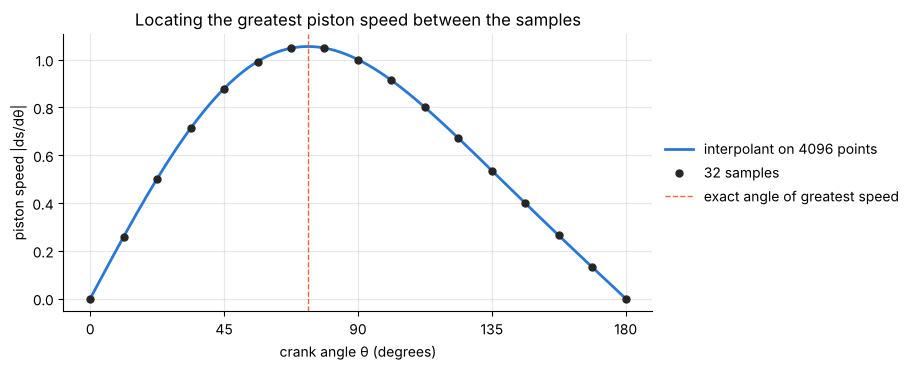

In [9]:
N, M = 32, 4096
theta = 2 * np.pi * np.arange(N) / N
theta_fine = 2 * np.pi * np.arange(M) / M
speed_coarse = np.abs(fft_derivative(position(theta)))
speed_fine = np.abs(fourier_interpolate(fft_derivative(position(theta)), M))

first_half = theta_fine <= np.pi
angle = theta_fine[first_half][np.argmax(speed_fine[first_half])]
angle_coarse = theta[np.argmax(speed_coarse[: N // 2 + 1])]
angle_exact = brentq(acceleration, 1.0, 2.0)
spacing = 2 * np.pi / M

print(f"best of the 32 samples:   {np.degrees(angle_coarse):.3f}°")
print(f"best of 4096 fine points: {np.degrees(angle):.3f}°   speed there {speed_fine[first_half].max():.7f}")
print(f"exact (root of d²s/dθ²):  {np.degrees(angle_exact):.3f}°   speed there {abs(velocity(angle_exact)):.7f}")
print(f"error {angle - angle_exact:.2e} rad = {np.degrees(angle - angle_exact):.3f}°, fine spacing {spacing:.2e} rad = {np.degrees(spacing):.3f}°, "
      f"ratio {abs(angle - angle_exact) / spacing:.2f}")

fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.plot(np.degrees(theta_fine[first_half]), speed_fine[first_half], label="interpolant on 4096 points")
ax.plot(np.degrees(theta[: N // 2 + 1]), speed_coarse[: N // 2 + 1], "o", color="0.15", ms=5, label="32 samples")
ax.axvline(np.degrees(angle_exact), color="C1", lw=1, ls="--", label="exact angle of greatest speed")
ax.set(xlabel="crank angle θ (degrees)", ylabel="piston speed |ds/dθ|", xticks=[0, 45, 90, 135, 180],
       title="Locating the greatest piston speed between the samples")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [10]:
# verify: against the exact root, and that the interpolant itself is not what limits the accuracy
assert abs(acceleration(angle_exact)) < 1e-10
assert abs(angle - angle_exact) <= spacing / 2                  # the nearest fine-grid point to the exact angle
assert np.abs(speed_fine - np.abs(velocity(theta_fine))).max() < 1e-11
assert abs(speed_fine[first_half].max() - abs(velocity(angle_exact))) < 1e-6
assert abs(angle_coarse - angle_exact) > 50 * abs(angle - angle_exact)

**Answer.** The piston is fastest at $\theta = 73.213°$ according to the fine grid, against the
exact $73.175°$. The error, $6.6\times10^{-4}$ rad or $0.038°$, is 0.43 of the fine spacing
($1.5\times10^{-3}$ rad, $0.088°$): it is the distance from the exact angle to the nearest
fine-grid point and nothing more, since the interpolated speed itself is correct to about
$10^{-12}$. The best of the 32 original samples is at $78.75°$, more than a hundred times
further off. The greatest speed, 1.0546 times $r$ per radian of crank angle, comes a little before
$90°$ because of the finite rod length. To locate a maximum more finely still, raise $M$ or
apply a root finder to the interpolated acceleration.

## Exercise 5

Repeat the noisy-data example of 2.9 with a poorer sensor, $\sigma = 10^{-4}$, $N = 256$ and
`np.random.default_rng(1)`. Compute the largest error of the filtered acceleration for
every cut-off from 2 to 12 and report the best cut-off. Is it the one suggested by the noise
floor $\sigma/\sqrt N$? Then do the same for the velocity (first derivative): how much does
filtering help there, and why less?

The noise floor is now a hundred times higher, so fewer wavenumbers carry signal and the
cut-off must come down. Two errors compete. A low cut-off removes signal (truncation error,
which falls quickly as the cut-off rises), a high one lets in noise multiplied by $k^m$ (which
rises). The best cut-off is where the two balance. By Parseval's identity the noise that
passes the filter has the root-mean-square size $\sigma\big(\tfrac1N\sum_{|k| \le K} k^{2m}\big)^{1/2}$ after
$m$ differentiations.

In [11]:
N, sigma = 256, 1e-4
theta = 2 * np.pi * np.arange(N) / N
k = np.fft.fftfreq(N, 1 / N)
measured = position(theta) + sigma * np.random.default_rng(1).standard_normal(N)

amplitude_clean = np.abs(np.fft.fft(position(theta))) / N
above_floor = np.flatnonzero(amplitude_clean[: N // 2] > sigma / np.sqrt(N))
print(f"noise floor σ/√N = {sigma / np.sqrt(N):.2e}; the exact signal is above it at k = {above_floor}, "
      f"and |c_6| = {amplitude_clean[6]:.2e} is just below")

cutoffs = np.arange(2, 13)
results = {}
for order, exact, name in ((2, acceleration, "acceleration"), (1, velocity, "velocity")):
    raw = fft_derivative(measured, order) - exact(theta)
    filtered = np.array([fft_derivative(low_pass(measured, c), order) - exact(theta) for c in cutoffs])
    truncation = np.array([fft_derivative(low_pass(position(theta), c), order) - exact(theta) for c in cutoffs])
    noise_rms = np.array([sigma * np.sqrt(np.mean(np.where(np.abs(k) <= c, k, 0.0) ** (2 * order))) for c in cutoffs])
    results[name] = dict(raw=raw, filtered=filtered, truncation=truncation, noise_rms=noise_rms,
                         raw_rms_predicted=sigma * np.sqrt(np.mean(k ** (2 * order))))
    largest = np.abs(filtered).max(axis=1)
    best = cutoffs[np.argmin(largest)]
    print(f"\n{name}: largest error unfiltered {np.abs(raw).max():.2e}")
    print("   cut-off:       " + "".join(f"{c:9d}" for c in cutoffs))
    print("   largest error: " + "".join(f"{e:9.1e}" for e in largest))
    print(f"   best cut-off {best}: {largest.min():.2e}, improvement {np.abs(raw).max() / largest.min():.0f} times;"
          f"   cut-off 4: {largest[cutoffs == 4][0]:.2e}")

noise floor σ/√N = 6.25e-06; the exact signal is above it at k = [0 1 2 4], and |c_6| = 4.64e-06 is just below

acceleration: largest error unfiltered 1.84e+00
   cut-off:               2        3        4        5        6        7        8        9       10       11       12
   largest error:   1.0e-02  1.1e-02  5.1e-04  5.6e-04  4.9e-04  5.8e-04  5.7e-04  1.2e-03  1.4e-03  1.7e-03  2.7e-03
   best cut-off 6: 4.88e-04, improvement 3762 times;   cut-off 4: 5.06e-04

velocity: largest error unfiltered 2.35e-02
   cut-off:               2        3        4        5        6        7        8        9       10       11       12
   largest error:   2.6e-03  2.6e-03  1.3e-04  1.2e-04  1.1e-04  1.3e-04  1.1e-04  1.7e-04  1.9e-04  2.0e-04  2.7e-04
   best cut-off 8: 1.06e-04, improvement 222 times;   cut-off 4: 1.26e-04


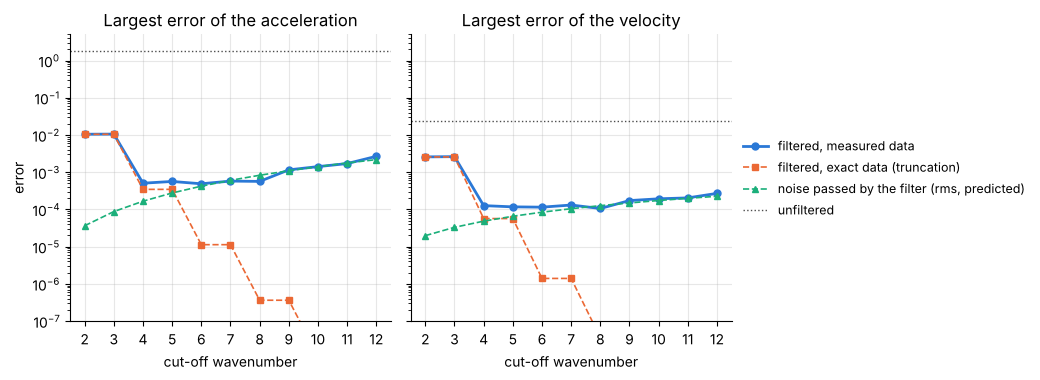

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    ax.semilogy(cutoffs, np.abs(r["filtered"]).max(axis=1), "o-", ms=5, label="filtered, measured data")
    ax.semilogy(cutoffs, np.abs(r["truncation"]).max(axis=1), "s--", ms=4, lw=1.2, label="filtered, exact data (truncation)")
    ax.semilogy(cutoffs, r["noise_rms"], "^--", ms=4, lw=1.2, label="noise passed by the filter (rms, predicted)")
    ax.axhline(np.abs(r["raw"]).max(), color="0.3", lw=1, ls=":", label="unfiltered")
    ax.set(xlabel="cut-off wavenumber", title=f"Largest error of the {name}", ylim=(1e-7, 5), xticks=cutoffs)
axes[0].set_ylabel("error")
axes[1].legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
fig.tight_layout()

The Parseval prediction is an average over all possible noise samples, and one sample of 256
numbers can sit well above or below it at the few low wavenumbers that pass the filter. So the
prediction is tested against an ensemble of 400 fresh noise samples, and the sample of this
exercise is compared with both.

In [13]:
# verify: the Parseval predictions against a Monte Carlo ensemble, and this sample against the predictions
noise_hat = np.fft.fft(sigma * np.random.default_rng(2).standard_normal((400, N)), axis=1)
for order, (name, r) in zip((2, 1), results.items()):
    raw_rms = np.sqrt(np.mean(r["raw"] ** 2))
    assert 0.8 < raw_rms / r["raw_rms_predicted"] < 1.25                                   # unfiltered: all 256 modes, little scatter
    ensemble_rms = np.array([np.sqrt(np.mean(np.real(np.fft.ifft((1j * k) ** order * (np.abs(k) <= c) * noise_hat, axis=1)) ** 2))
                             for c in cutoffs])
    assert np.abs(ensemble_rms / r["noise_rms"] - 1).max() < 0.1
    expected = np.sqrt(r["noise_rms"] ** 2 + np.mean(r["truncation"] ** 2, axis=1))        # noise and truncation add in the mean square
    this_sample = np.sqrt(np.mean(r["filtered"] ** 2, axis=1))
    print(f"{name}: rms error of this sample / expected, for each cut-off: {np.round(this_sample / expected, 2)}")
    print(f"   cut-off with the smallest expected rms error: {cutoffs[np.argmin(expected)]}")
    assert np.all((this_sample / expected > 0.2) & (this_sample / expected < 1.2)) and cutoffs[np.argmin(expected)] == 4
best = {name: int(cutoffs[np.argmin(np.abs(r["filtered"]).max(axis=1))]) for name, r in results.items()}
gain = {name: np.abs(r["raw"]).max() / np.abs(r["filtered"]).max(axis=1).min() for name, r in results.items()}
assert 4 <= best["acceleration"] <= 8 and 4 <= best["velocity"] <= 8 and above_floor.max() == 4
assert gain["acceleration"] > 1000 and 50 < gain["velocity"] < 1000

acceleration: rms error of this sample / expected, for each cut-off: [1.   1.   0.89 0.77 0.47 0.36 0.35 0.49 0.4  0.35 0.58]
   cut-off with the smallest expected rms error: 4
velocity: rms error of this sample / expected, for each cut-off: [1.   1.   0.81 0.73 0.53 0.44 0.41 0.48 0.43 0.39 0.53]
   cut-off with the smallest expected rms error: 4


**Answer.** For the acceleration the best cut-off is 6, with a largest error of
$4.9\times10^{-4}$ against 1.8 without a filter, an improvement of about 3800 times. The noise
floor $\sigma/\sqrt N = 6.3\times10^{-6}$ suggests a cut-off of 4, the last wavenumber whose exact
amplitude is above it, and that gives $5.1\times10^{-4}$: practically the same. The amplitude at
$k = 6$ is $4.6\times10^{-6}$, just under the floor, so keeping it is a toss-up, and the error
is flat from 4 to 8. Which of those wins depends on the noise sample. This one happens to be
quiet at low wavenumbers (for cut-offs of 6 and above its rms error is between 0.35 and 0.6 of
the expected value), which favours
the higher cut-offs. Averaged over many samples the smallest error is at cut-off 4, as the
noise floor says.

For the velocity the best cut-off is 8 with a largest error of $1.1\times10^{-4}$, against
$2.3\times10^{-2}$ unfiltered: an improvement of about 220 times, much less than for the
acceleration. One differentiation multiplies the noise at wavenumber $k$ by $k$, two by $k^2$,
so the unfiltered velocity is damaged far less to begin with (rms error $\sigma(N/2)/\sqrt3$
against $\sigma(N/2)^2/\sqrt5$), while the filtered errors of the two are of similar size. The
higher the derivative, the more a filter is needed.